In [35]:
import numpy as np
import pandas as pd

# Set seed for reproducibility
np.random.seed(42)

In [48]:
def create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"]):

    # Generate client-level data
    client_ids = np.arange(1, num_clients + 1)

    # Income: Should follow a right skewed distribution (log-normal)
    # Adjusting the income distribution to follow a log-normal distribution (right-skewed, long tail)
    mean_income = 10  # Log-normal mean
    sigma_income = 0.6  # Log-normal standard deviation

    # Generate income values (skewed distribution)
    client_incomes = np.random.lognormal(mean=mean_income, sigma=sigma_income, size=num_clients)
    client_incomes = np.interp(client_incomes, (client_incomes.min(), client_incomes.max()), (20000, 200000))

    #client_incomes = np.random.uniform(20000, 100000, size=num_clients)  # Continuous feature: income
    client_spending_categories = np.random.choice(client_categories, size=num_clients)  # Categorical feature

    # Map spending categories to a numerical effect (low = 0.8, mid = 1, high = 1.2)
    category_effects = {"low_spender": 0.8, "mid_spender": 1, "high_spender": 1.2}
    product_base_prices = {1: (10, 30), 2: (15, 50), 3: (5, 25)}

    data = []
    for _ in range(num_transactions):
        client = np.random.choice(client_ids)
        product = np.random.randint(1, num_products + 1)

        # Determine product base price range
        base_price_min, base_price_max = product_base_prices[product]

        # Client attributes
        income = client_incomes[client - 1]
        category = client_spending_categories[client - 1]
        category_multiplier = category_effects[category]

        # Price is sampled randomly within the product's base range
        price = np.random.uniform(base_price_min, base_price_max)

        # Amount bought depends on price (inverse relation) and income (higher income buys more)
        base_demand = np.random.uniform(5, 20)  # Base demand per product
        income_factor = (income / 200000)  # Scaled income effect (higher income = more purchases)
        
        amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (1 + price / base_price_max))) + np.random.normal(0, 1))

        data.append([client, product, price, amount_bought, income, category])

    # Create DataFrame
    df = pd.DataFrame(data, columns=["client_id", "product_id", "offered_price", "amount_bought", "income", "client_category"])
    df["amount_bought"] = df["amount_bought"].round().astype(int)
    df["amount_bought"] = df["amount_bought"].clip(lower=0)  # Ensure no negative values

    df_name_to_save = f"synthetic_dataset_{num_clients}clients_{num_transactions}trans.csv"
    df.to_csv("data/" + df_name_to_save, index=False)
    return df, df_name_to_save




In [55]:
df, df_name = create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"])
df

,client_id,product_id,offered_price,amount_bought,income,client_category
0,72,2,46.827680,2,33566.275842,high_spender
1,28,1,11.559167,1,47892.326531,low_spender
2,48,1,13.571141,1,83560.288918,mid_spender
3,92,3,5.995808,3,29973.032107,low_spender
4,27,2,18.798284,3,43653.338915,low_spender
...,...,...,...,...,...,...
995,33,1,10.476311,4,75102.280655,high_spender
996,15,1,14.828117,2,54640.362488,high_spender
997,23,1,10.205266,4,61228.133607,low_spender
998,82,1,22.338874,2,73464.571056,low_spender


In [56]:
df_loaded = pd.read_csv("data/synthetic_dataset_100clients_1000trans.csv")
df_loaded

,client_id,product_id,offered_price,amount_bought,income,client_category
0,72,2,46.827680,2,33566.275842,high_spender
1,28,1,11.559167,1,47892.326531,low_spender
2,48,1,13.571141,1,83560.288918,mid_spender
3,92,3,5.995808,3,29973.032107,low_spender
4,27,2,18.798284,3,43653.338915,low_spender
...,...,...,...,...,...,...
995,33,1,10.476311,4,75102.280655,high_spender
996,15,1,14.828117,2,54640.362488,high_spender
997,23,1,10.205266,4,61228.133607,low_spender
998,82,1,22.338874,2,73464.571056,low_spender


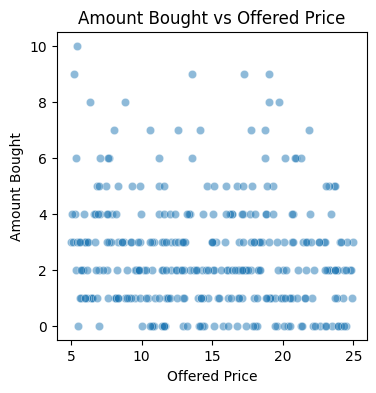

In [63]:
import matplotlib.pyplot as plt
import seaborn as sns
df_filtered = df_loaded[df_loaded['product_id'] == 3]

plt.figure(figsize=(4, 4))
sns.scatterplot(x=df_filtered["offered_price"], y=df_filtered["amount_bought"], alpha=0.5)
plt.xlabel("Offered Price")
plt.ylabel("Amount Bought")
plt.title("Amount Bought vs Offered Price")
plt.show()
